<a href="https://colab.research.google.com/github/edoardo2496/data_science_portfolio/blob/main/Iron-Commodity-Forecasting-Lab/Iron_Commodity_Forecasting_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚀 Iron-Price-OU-TimesFM-Engine
*Stochastic Modeling (Ornstein-Uhlenbeck) vs. Deep Learning Foundation Models (Google TimesFM) for Raw Iron Price Forecasting and Procurement Optimization.*

---
### 📋 Notebook Index:
1. **Setup & Libraries**: Environment setup and package installation (`timesfm`, `statsmodels`, `scikit-learn`).
2. **Data Loading & Preprocessing**: Importing and filtering historical data (from 2005 onwards, ADF validation).
3. **Ornstein-Uhlenbeck (OU) Model**: Parameter calibration, Half-Life calculation, and operational **Z-score** signal.
4. **Monte Carlo Simulation & Analytics**: Generating 24-month forward scenarios and comparing with Itô's Lemma.
5. **Google TimesFM Forecasting**: Applying Google's foundation transformer for zero-shot time series forecasting.
6. **Comparison & Final Visualization**: Visual and quantitative benchmarking between both approaches.
---

#Section 1. Libraries & Dependences

In [6]:
# ==========================================
# BLOCCO 1: Setup dell'Ambiente e Librerie
# ==========================================

# Installazione delle dipendenze necessarie (incluso timesfm di Google)
!pip install -q timesfm statsmodels scikit-learn openpyxl matplotlib seaborn pandas numpy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from sklearn.linear_model import LinearRegression
import timesfm

# Configurazione grafica pulita
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)

print("Librerie caricate con successo!")

Librerie caricate con successo!


#Section 2. Data Loading & Preprocessing

Dataset loaded. Total observations from 2005: 261
Latest available price (2026-09-01): 0.2524 €/kg


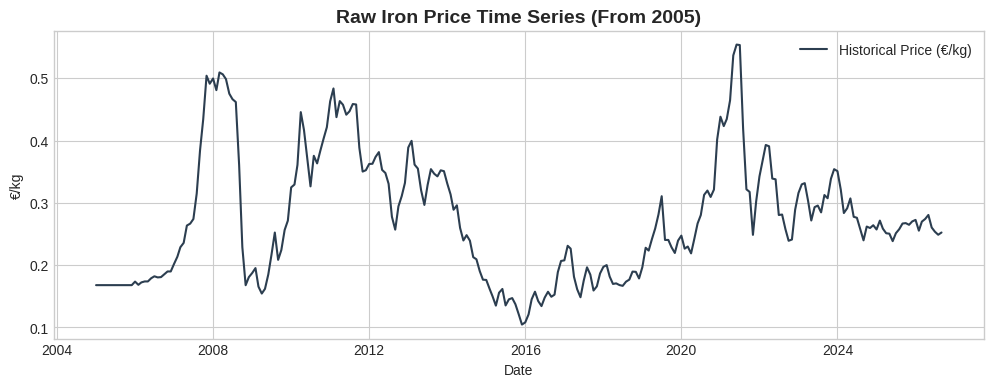

In [8]:
# ==========================================
# BLOCK 2: Data Loading & Preprocessing
# ==========================================

# Load the dataset (make sure 'dati_ferro_grezzo.xlsx' is uploaded in your Colab session)
file_path = '/content/dati_ferro_grezzo.xlsx'

df = pd.read_excel(file_path)
df['data'] = pd.to_datetime(df['data'])

# Filter from 2005 onwards (as validated by ADF test with p < 0.05)
df = df[df['data'] >= '2005-01-01'].reset_index(drop=True)

S = df['euro_kg'].values
dates = df['data'].values

print(f"Dataset loaded. Total observations from 2005: {len(df)}")
print(f"Latest available price ({df['data'].iloc[-1].strftime('%Y-%m-%d')}): {S[-1]:.4f} €/kg")

# Quick visualization of the time series
plt.figure(figsize=(12, 4))
plt.plot(df['data'], S, color='#2c3e50', lw=1.5, label='Historical Price (€/kg)')
plt.title('Raw Iron Price Time Series (From 2005)', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('€/kg')
plt.legend()
plt.show()

#Section 3. OU Model Calibration & Z-Score (Code Cell)

In [9]:
# ==========================================
# BLOCK 3: OU Model Calibration & Z-Score
# ==========================================

dt = 1/12  # Monthly step

# ADF Stationarity test
adf_stat, adf_p, *_ = adfuller(S)

# Calibration via linear regression (S_{t+1} = a + b*S_t)
x = S[:-1].reshape(-1, 1)
y = S[1:]
reg = LinearRegression().fit(x, y)
b = reg.coef_[0]
a_coef = reg.intercept_
residuals = y - reg.predict(x)
sigma_resid = np.std(residuals)

# Continuous SDE parameters
theta = (1 - b) / dt              # Mean reversion speed
mu = a_coef / (1 - b)             # Long-term mean
sigma = sigma_resid / np.sqrt(dt) # Annualized volatility
half_life_mesi = np.log(2) / theta * 12

# Current Z-score calculation
S0 = S[-1]
z_score = (S0 - mu) / sigma_resid

if z_score < -1.5:
    status, action = "ATTRACTIVE (Low Price)", "CONSIDER VOLUME PURCHASING"
elif z_score > 1.5:
    status, action = "EXPENSIVE (Downward Risk Zone)", "PURCHASE STRICTLY AS NEEDED"
else:
    status, action = "NEUTRAL (In line with historical mean)", "NORMAL PURCHASING"

print(f"--- OU MODEL PARAMETERS ---")
print(f"ADF p-value: {adf_p:.4f} ({'Stationary / Mean-Reverting' if adf_p < 0.05 else 'Non-stationary'})")
print(f"Theta (reversion speed): {theta:.4f}")
print(f"Mu (long-term mean): {mu:.4f} €/kg")
print(f"Sigma (annualized volatility): {sigma:.4f}")
print(f"Half-life: {half_life_mesi:.1f} months\n")

print(f"--- CURRENT OPERATIONAL SIGNAL ---")
print(f"Current Price (S0): {S0:.4f} €/kg")
print(f"Z-score: {z_score:.2f}")
print(f"Status: {status} -> {action}")

--- OU MODEL PARAMETERS ---
ADF p-value: 0.0115 (Stationary / Mean-Reverting)
Theta (reversion speed): 0.4964
Mu (long-term mean): 0.2830 €/kg
Sigma (annualized volatility): 0.0963
Half-life: 16.8 months

--- CURRENT OPERATIONAL SIGNAL ---
Current Price (S0): 0.2524 €/kg
Z-score: -1.10
Status: NEUTRAL (In line with historical mean) -> NORMAL PURCHASING


/tmp/ipykernel_852/183393495.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, *_ = adfuller(S)


#Section 4. Monte Carlo and Analytical Simulation via Itô's Lemma (Code Cell)

##This block runs the 24-month Monte Carlo simulation and computes the exact analytical forecasts.


In [10]:
# ==========================================
# BLOCK 4: Monte Carlo Simulation & Itô's Analytics
# ==========================================

# 1. Analytic forecast function via Itô's Lemma
def ou_analytic_forecast(S0_val, mesi, theta_param, mu_param, sigma_param):
    t = mesi / 12
    expected = S0_val * np.exp(-theta_param * t) + mu_param * (1 - np.exp(-theta_param * t))
    fut_std = np.sqrt((sigma_param**2 / (2 * theta_param)) * (1 - np.exp(-2 * theta_param * t)))
    return expected, fut_std

# 2. Monte Carlo Simulation (Euler-Maruyama)
np.random.seed(42)
N_SIM = 10_000
N_MONTHS = 24

paths = np.zeros((N_SIM, N_MONTHS + 1))
paths[:, 0] = S0

for t in range(N_MONTHS):
    dW = np.random.normal(0, np.sqrt(dt), N_SIM)
    paths[:, t+1] = (paths[:, t]
                     + theta * (mu - paths[:, t]) * dt
                     + sigma * dW)

final_prices = paths[:, -1]
p5, p25, p50, p75, p95 = np.percentile(final_prices, [5, 25, 50, 75, 95])

# Print Text Outputs
print(f"\n{'='*55}")
print(f"  ITÔ'S LEMMA ANALYTIC FORECASTS")
print(f"{'='*55}")
for m in [3, 6, 12, 24]:
    att, std = ou_analytic_forecast(S0, m, theta, mu, sigma)
    print(f"  {m:>2}m → Expected: {att:.4f}  95% CI: [{att-1.96*std:.4f}, {att+1.96*std:.4f}]")

print(f"\n{'─'*55}")
print(f"  MONTE CARLO — 24-Month Distribution (N={N_SIM:,})")
print(f"{'─'*55}")
print(f"  P5: {p5:.4f}  P25: {p25:.4f}  P50: {p50:.4f}  P75: {p75:.4f}  P95: {p95:.4f}")


  ITÔ'S LEMMA ANALYTIC FORECASTS
   3m → Expected: 0.2560  95% CI: [0.1672, 0.3448]
   6m → Expected: 0.2591  95% CI: [0.1407, 0.3776]
  12m → Expected: 0.2644  95% CI: [0.1141, 0.4146]
  24m → Expected: 0.2717  95% CI: [0.0958, 0.4476]

───────────────────────────────────────────────────────
  MONTE CARLO — 24-Month Distribution (N=10,000)
───────────────────────────────────────────────────────
  P5: 0.1235  P25: 0.2103  P50: 0.2728  P75: 0.3333  P95: 0.4209


#Section 5. Google TimesFM Integration (Code Cell)

##Here we configure and load Google's foundation model to generate the zero-shot forecast.


In [15]:
# ==========================================
# BLOCK 5: Google TimesFM Forecasting
# ==========================================

import timesfm

# Orizzonte di previsione a 24 mesi (dati mensili)
horizon = 24

print("Loading TimesFM pre-trained foundational model...")
# Caricamento del modello ufficiale pre-addestrato PyTorch (v2.5)
model = timesfm.TimesFM_2p5_200M_torch.from_pretrained(
    "google/timesfm-2.5-200m-pytorch",
    torch_compile=False  # Disabilitato per un'esecuzione fluida su Colab T4 GPU
)

# Configurazione dei parametri tramite ForecastConfig
model.compile(
    timesfm.ForecastConfig(
        max_context=512,
        max_horizon=horizon,
        normalize_inputs=True,
        use_continuous_quantile_head=True,
        fix_quantile_crossing=True,
    )
)

print("Running zero-shot inference...")
# Esecuzione dell'inferenza zero-shot sui prezzi mensili del ferro grezzo (S)
point_forecast, quantile_forecast = model.forecast(
    horizon=horizon,
    inputs=[S.astype(np.float32)]
)

# Estrazione delle previsioni e dei confini di rischio (10° e 90° percentile)
tfm_forecast = point_forecast[0]
tfm_lower = quantile_forecast[0, :, 1]  # Scenario ribassista (Q10)
tfm_upper = quantile_forecast[0, :, 9]  # Scenario rialzista (Q90)

print("Inference completed successfully!")

Loading TimesFM pre-trained foundational model...
Running zero-shot inference...
Inference completed successfully!


#Section 6. Difference between Itto's Lemma and Google TimesFM TLM

In [16]:
# ==========================================
# BLOCK 6: Quantitative Comparison Table
# ==========================================

comparison_data = []
months_list = [3, 6, 12, 24]

for m in months_list:
    # Valore atteso OU (Lemma di Itô)
    ou_exp, ou_std = ou_analytic_forecast(S0, m, theta, mu, sigma)
    # Valore previsto TimesFM (indice m-1 nell'array mensile)
    tfm_val = tfm_forecast[m-1] if m <= len(tfm_forecast) else np.nan

    comparison_data.append({
        "Horizon": f"{m} Months",
        "OU Expected (€/kg)": round(ou_exp, 4),
        "OU 95% CI Upper": round(ou_exp + 1.96 * ou_std, 4),
        "OU 95% CI Lower": round(ou_exp - 1.96 * ou_std, 4),
        "TimesFM Forecast (€/kg)": round(tfm_val, 4)
    })

df_comparison = pd.DataFrame(comparison_data)
print("\n" + "="*70)
print("  COMPARISON BENCHMARK: ORNSTEIN-UHLENBECK vs GOOGLE TIMESFM")
print("="*70)
display(df_comparison)


  COMPARISON BENCHMARK: ORNSTEIN-UHLENBECK vs GOOGLE TIMESFM


,Horizon,OU Expected (€/kg),OU 95% CI Upper,OU 95% CI Lower,TimesFM Forecast (€/kg)
0,3 Months,0.2560,0.3448,0.1672,0.2525
1,6 Months,0.2591,0.3776,0.1407,0.2452
2,12 Months,0.2644,0.4146,0.1141,0.2395
3,24 Months,0.2717,0.4476,0.0958,0.2321
